# 05 · The Language Tax

> **The equity and economics crux.** Tokenizers are trained on English-heavy
> text, so English compresses into few tokens while other languages fragment
> into many more for the *same meaning*. Since pricing is per token, that is a
> cost tax, a context tax, and a modeling-quality tax.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## The same sentence, every language

In [2]:
from src.bpe import BPETokenizer
from src.datasets.corpora import parallel_sentences, training_corpus
from src.evaluation.cost import cost_across_languages
from src.probes.multilingual import language_tax

tok = BPETokenizer().train(training_corpus(60_000), vocab_size=512)
sentences = parallel_sentences()

taxes = language_tax(tok, sentences)
costs = {c.language: c for c in cost_across_languages(tok, sentences, usd_per_1k=0.01)}

for t in sorted(taxes, key=lambda x: x.num_tokens):
    print(f"{t.language:>12}  {t.num_tokens:>3} tokens  x{t.ratio_to_english:.2f}")

     English   17 tokens  x1.00
      French   22 tokens  x1.29
     Spanish   24 tokens  x1.41
     Chinese   24 tokens  x1.41
      Korean   25 tokens  x1.47
      German   26 tokens  x1.53
  Portuguese   27 tokens  x1.59
      Arabic   29 tokens  x1.71
   Ukrainian   39 tokens  x2.29
    Japanese   42 tokens  x2.47
       Greek   49 tokens  x2.88
       Hindi   61 tokens  x3.59


In [3]:
rows = []
for t in taxes:
    c = costs[t.language]
    rows.append(
        {
            "language": t.language,
            "text": t.text,
            "tokens": t.num_tokens,
            "ratio_to_english": round(t.ratio_to_english, 3),
            "usd_per_call": round(c.usd, 6),
        }
    )
print("saved:", save_json("05_language_tax", rows))

saved: /workspaces/tokenization_101/outputs/data/05_language_tax.json


saved: /workspaces/tokenization_101/outputs/figures/05_language_tax.png


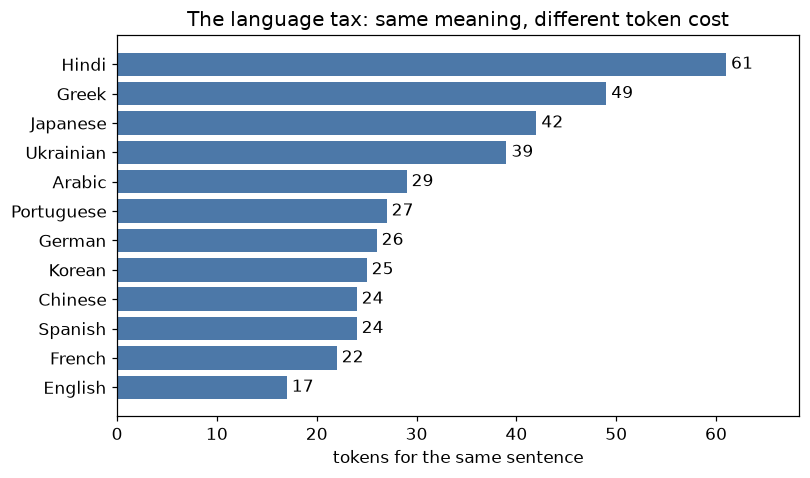

In [4]:
from src.visualisation import plot_language_tax

fig = plot_language_tax(taxes)
print("saved:", save_figure(fig, "05_language_tax"))
plt.show()

## The same meaning, a multiple of the cost

saved: /workspaces/tokenization_101/outputs/figures/05_cost_ratio.png


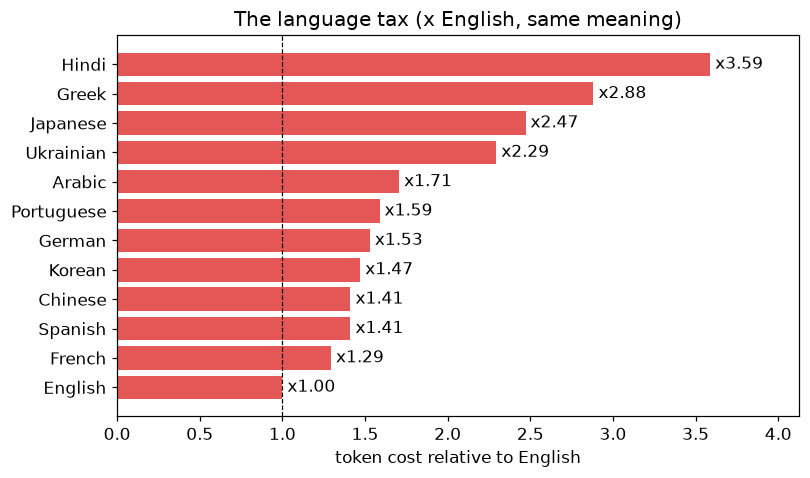

In [5]:
ordered = sorted(rows, key=lambda r: r["ratio_to_english"])
labels = [r["language"] for r in ordered]
ratios = [r["ratio_to_english"] for r in ordered]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, ratios, color="#E45756")
ax.axvline(1.0, color="black", lw=0.8, ls="--")
ax.set_xlabel("token cost relative to English")
ax.set_title("The language tax (x English, same meaning)")
ax.set_xlim(0, max(ratios) * 1.15)  # headroom so the "x2.90" labels are not clipped
for y, r in enumerate(ratios):
    ax.text(r, y, f" x{r:.2f}", va="center")
print("saved:", save_figure(fig, "05_cost_ratio"))
plt.show()

**Takeaway.** The tax is a measured ratio on matched content, not an anecdote.
Non-Latin scripts especially pay 2-3x or more: more money, less context, shorter
effective sequences. Measure it before scoping multilingual systems.